<a href="https://colab.research.google.com/github/AnjiReddyDondeti/Credit-Card-Fraud-Detection-/blob/main/Creating_Watermarks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
plt.rcParams['image.cmap'] = 'gray'
plt.rcParams['figure.figsize'] = (15, 15)

if 'google.colab' in str(get_ipython()):
    print("Downloading Code to Colab Environment")
    !wget https://www.dropbox.com/sh/f8ae3j0nbrflife/AAAy-WwcREtWOGgoEbFLDPANa?dl=1 -O module-code.zip -q --show-progress
    !unzip -qq module-code.zip
else:
    pass

module-code.zip     100%[===================>]  21.78M  23.3MB/s    in 0.9s    
mapname:  conversion of  failed


(730, 1094, 3) 3 uint8
(2436, 2623, 4) 3 uint8


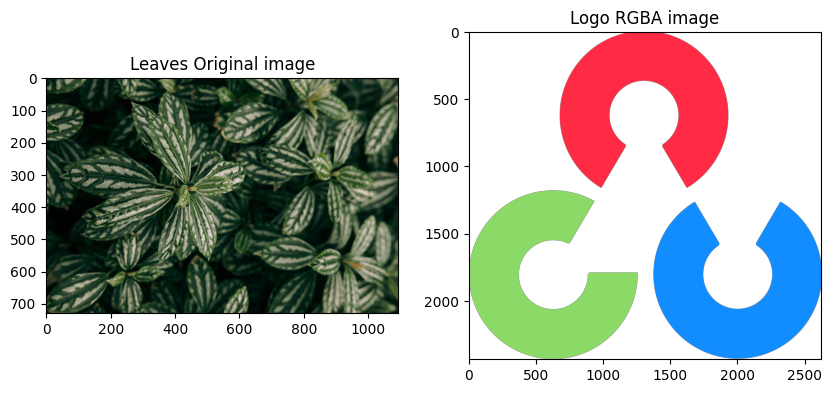

In [18]:
# reading the images
leaves = cv2.imread('/content/leaves.jpg', cv2.IMREAD_UNCHANGED)
logo = cv2.imread('/content/opencv_logo.png', cv2.IMREAD_UNCHANGED)

# checking the dimensions and channel count
print(leaves.shape, leaves.ndim, leaves.dtype)
print(logo.shape, logo.ndim, logo.dtype)

# for ease of display, converting BGRA to RGBA
logo_rgba = cv2.cvtColor(logo, cv2.COLOR_BGRA2RGBA)

# Dispalying the images
plt.figure(figsize=(10, 10))
plt.subplot(121); plt.imshow(leaves[:, :, ::-1]); plt.title('Leaves Original image')
plt.subplot(122); plt.imshow(logo_rgba); plt.title('Logo RGBA image');

In [19]:
# Resizing the logo
logo = cv2.resize(logo, None, fx=0.1, fy=0.1, interpolation=cv2.INTER_LINEAR)

# Retrieving the shapes of leaves and logo
leaves_height, leaves_width, _ = leaves.shape
logo_height, logo_width, _ = logo.shape

# printing height and width of leaves and resized logo
print(leaves_height, leaves_width)
print(logo_height, log_width)

730 1094
244 262


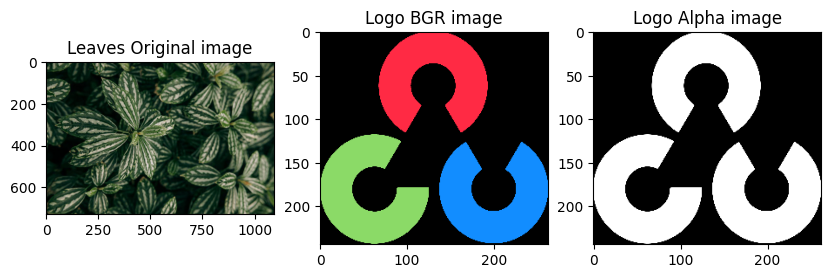

In [20]:
# separating the color cahnnels from logo
logo_bgr = logo[:, :, :3]
logo_alpha = logo[:, :, 3]

# displaying the images
plt.figure(figsize=(10, 10))
plt.subplot(131); plt.imshow(leaves[:, :, ::-1]); plt.title('Leaves Original image')
plt.subplot(132); plt.imshow(logo_bgr[:, :, ::-1]); plt.title('Logo BGR image')
plt.subplot(133); plt.imshow(logo_alpha); plt.title('Logo Alpha image');

547.0 365.0
416.0 243.0
678.0 487.0
(244, 262, 3) (244, 262, 4)


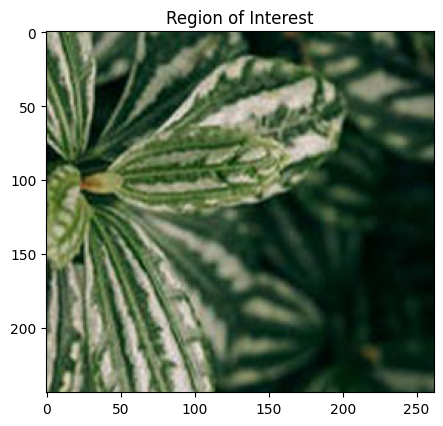

In [22]:
# cx and cy are center of the leaves image
cx = leaves_width / 2
cy = leaves_height / 2
print(cx, cy)
# tlc_x and tlc_y are top left corner points
tlc_x = cx - logo_width / 2
tlc_y = cy - logo_height / 2
print(tlc_x, tlc_y)
# btr_x and bt_y are bottem right corner points
btr_x = cx + logo_width / 2
btr_y = cy + logo_height / 2
print(btr_x, btr_y)
# selecting Region of interest from leaves image
ROI = leaves[int(tlc_y):int(btr_y), int(tlc_x):int(btr_x)]
print(ROI.shape, logo.shape)
# Displaying the ROI
plt.figure(figsize=(5, 5))
plt.imshow(ROI[:, :, ::-1]); plt.title('Region of Interest');

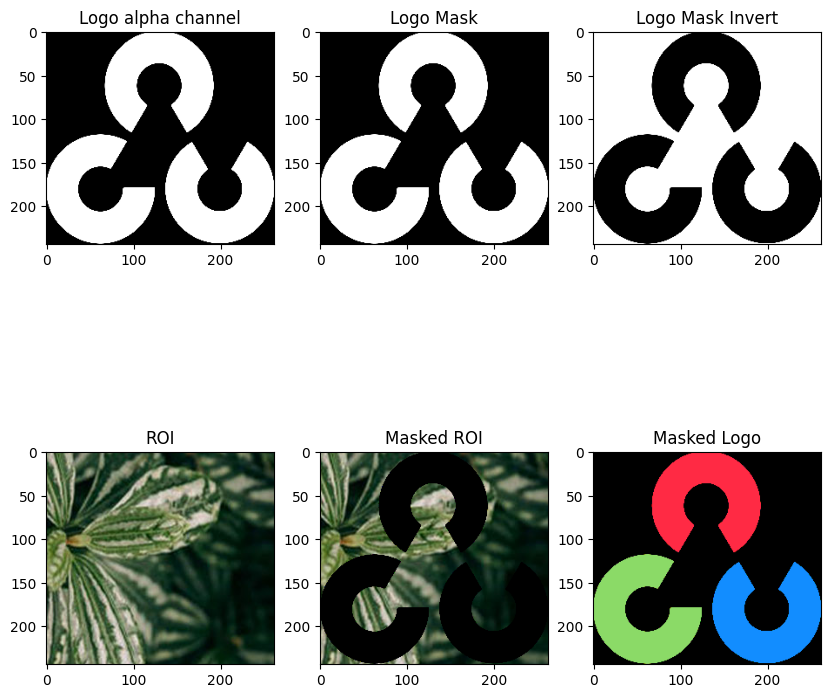

In [26]:
# Make the dimensions of the mask same as the input image.
# Since the background image is a 3-channel image, we create a 3 channel image for the mask.
logo_mask = cv2.merge([logo_alpha, logo_alpha, logo_alpha])

logo_mask_invert = cv2.bitwise_not(logo_mask)

# Use the mask to create the masked ROI region
masked_roi = cv2.bitwise_and(ROI, logo_mask_invert)

# Use the mask to create the masked logo region
masked_logo = cv2.bitwise_and(logo_bgr, logo_mask)

plt.figure(figsize=(10, 10))
plt.subplot(231); plt.imshow(logo_alpha); plt.title('Logo alpha channel')
plt.subplot(232); plt.imshow(logo_mask); plt.title('Logo Mask')
plt.subplot(233); plt.imshow(logo_mask_invert); plt.title('Logo Mask Invert')

plt.subplot(234); plt.imshow(ROI[:, :, ::-1]); plt.title('ROI')
plt.subplot(235); plt.imshow(masked_roi[:, :, ::-1]); plt.title('Masked ROI')
plt.subplot(236); plt.imshow(masked_logo[:, :, ::-1]); plt.title('Masked Logo');

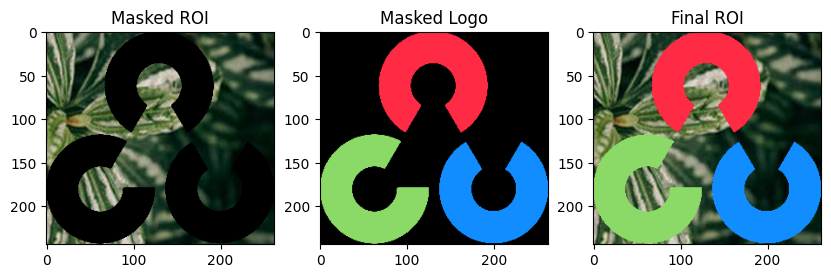

In [28]:
# combining both masked images to get what we want
ROI_final = cv2.bitwise_or(masked_roi, masked_logo)

plt.figure(figsize=(10, 10))
plt.subplot(131); plt.imshow(masked_roi[:, :, ::-1]); plt.title('Masked ROI')
plt.subplot(132); plt.imshow(masked_logo[:, :, ::-1]); plt.title('Masked Logo')
plt.subplot(133); plt.imshow(ROI_final[:, :, ::-1]); plt.title('Final ROI');

In [29]:
leaves_1 = leaves.copy()
ROI_1 = ROI_final.copy()

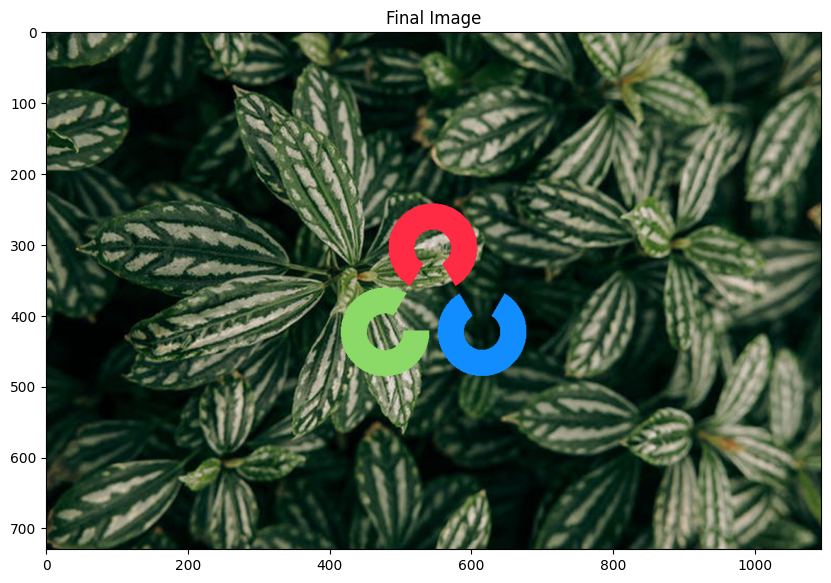

In [32]:
# Inserting our ROI to the leaves image
leaves_1[int(tlc_y):int(btr_y), int(tlc_x):int(btr_x)] = ROI_1
plt.figure(figsize=(10, 10))
plt.imshow(leaves_1[:, :, ::-1]); plt.title('Final Image');

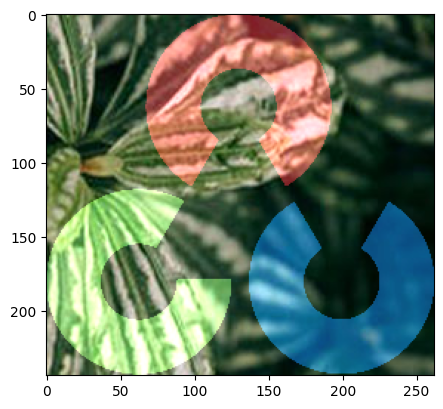

In [36]:
ROI_2 = ROI.copy()
watermark = cv2.addWeighted(ROI_2, 1, logo_bgr, 0.5, 0)
plt.figure(figsize=(5, 5))
plt.imshow(watermark[:, :, ::-1])

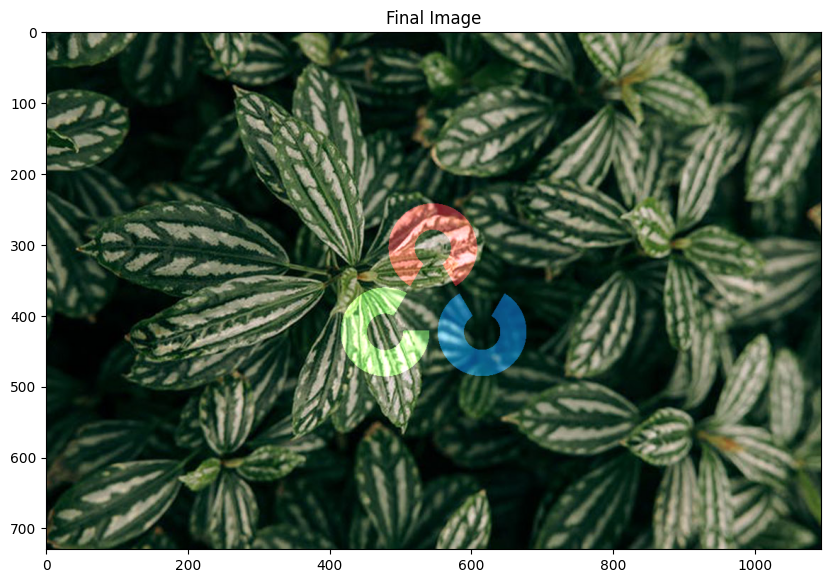

In [37]:
leaves_2 = leaves.copy()
leaves_2[int(tlc_y):int(btr_y), int(tlc_x):int(btr_x)] = watermark
plt.figure(figsize=(10, 10))
plt.imshow(leaves_2[:, :, ::-1]); plt.title('Final Image');

In [38]:
cv2.imwrite('Watermark.jpg', leaves_2)

True

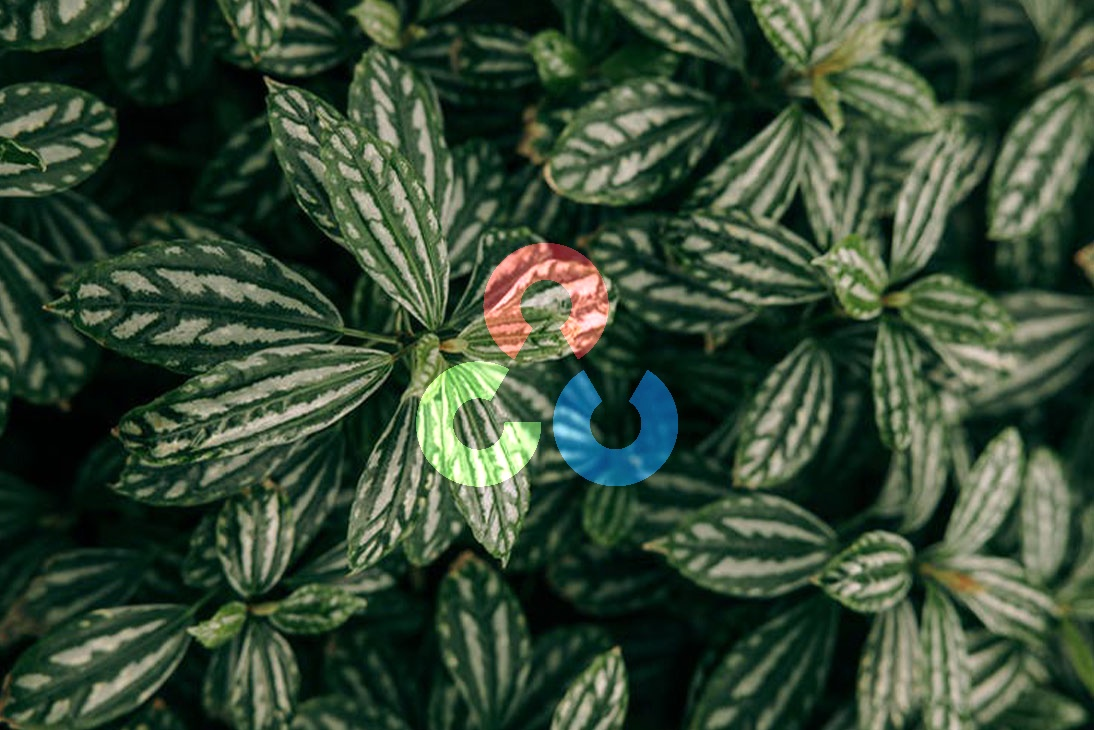

In [39]:
from IPython.display import Image
Image('Watermark.jpg')